In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device in use:', device)

Device in use: cuda


In [3]:
HP = {
    'batch_size': 16,
    'img_size': (224, 224),
    'learning_rate': 0.001,
    'epochs': 20,
    'optimizer': 'Adamax',
    'dropout_rate': 0.3,
    'dense_units': 256,
    'architecture': 'EfficientNetB3'
}

In [4]:
def prepare_data(data_dir):
    filepaths = []
    labels = []
    
    folds = os.listdir(data_dir)
    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        if os.path.isdir(foldpath):
            filelist = os.listdir(foldpath)
            for file in filelist:
                filepath = os.path.join(foldpath, file)
                filepaths.append(filepath)
                labels.append(fold)
    
    df = pd.DataFrame(data={'filepaths': filepaths, 'labels': labels})
    return df

In [5]:
data_dir = 'dataset/crop'
df = prepare_data(data_dir)
print(f'Shape of dataset is {df.shape}, numbers of labels {df["labels"].nunique()}')
df.head()

Shape of dataset is (45435, 2), numbers of labels 114


,filepaths,labels
0,dataset/crop\A10\00c09f406d31a0cd9402862fbd26d...,A10
1,dataset/crop\A10\00d4b7ea93ca1417393007c61c519...,A10
2,dataset/crop\A10\01169f9ba735dfcb46dab62bc5649...,A10
3,dataset/crop\A10\016fd73cdece1b76562ec526ba939...,A10
4,dataset/crop\A10\01ed4d81c5d733cbaa266b6ea7821...,A10


In [6]:
train, test = train_test_split(df, test_size=0.3, stratify=df['labels'], random_state=42)
test, valid = train_test_split(test, test_size=0.5, stratify=test['labels'], random_state=42)
train.shape, test.shape, valid.shape

((31804, 2), (6815, 2), (6816, 2))

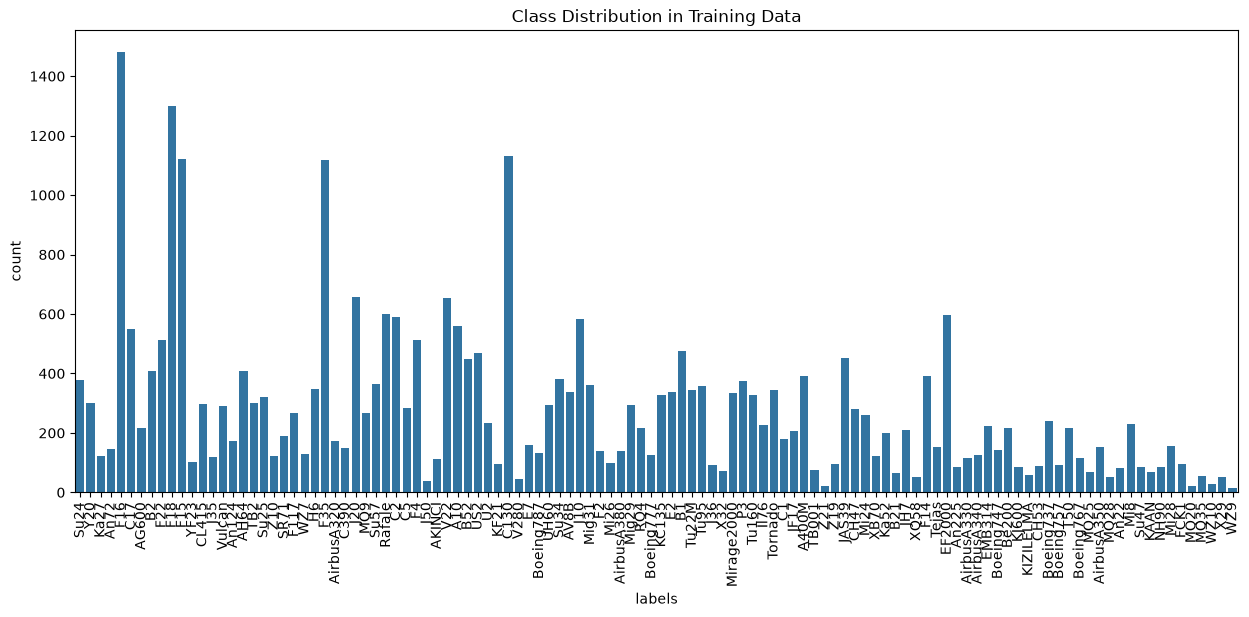

In [7]:
# Class Distribution
plt.figure(figsize=(15, 6))
sns.countplot(data=train, x='labels')
plt.title('Class Distribution in Training Data')
plt.xticks(rotation=90)
plt.show()

In [8]:
batch_size = 16
img_size = (224, 224)

unique_labels = sorted(train['labels'].unique())
class_indices = {label: i for i, label in enumerate(unique_labels)}

class AircraftDataset(Dataset):
    def __init__(self, dataframe, class_to_idx, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepaths']
        label_str = self.df.loc[idx, 'labels']
        label = self.class_to_idx[label_str]
        
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
            
        return image, label

transform = transforms.Compose([
    transforms.Resize(img_size),
    transforms.ToTensor()
])

train_dataset = AircraftDataset(train, class_indices, transform=transform)
valid_dataset = AircraftDataset(valid, class_indices, transform=transform)
test_dataset = AircraftDataset(test, class_indices, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

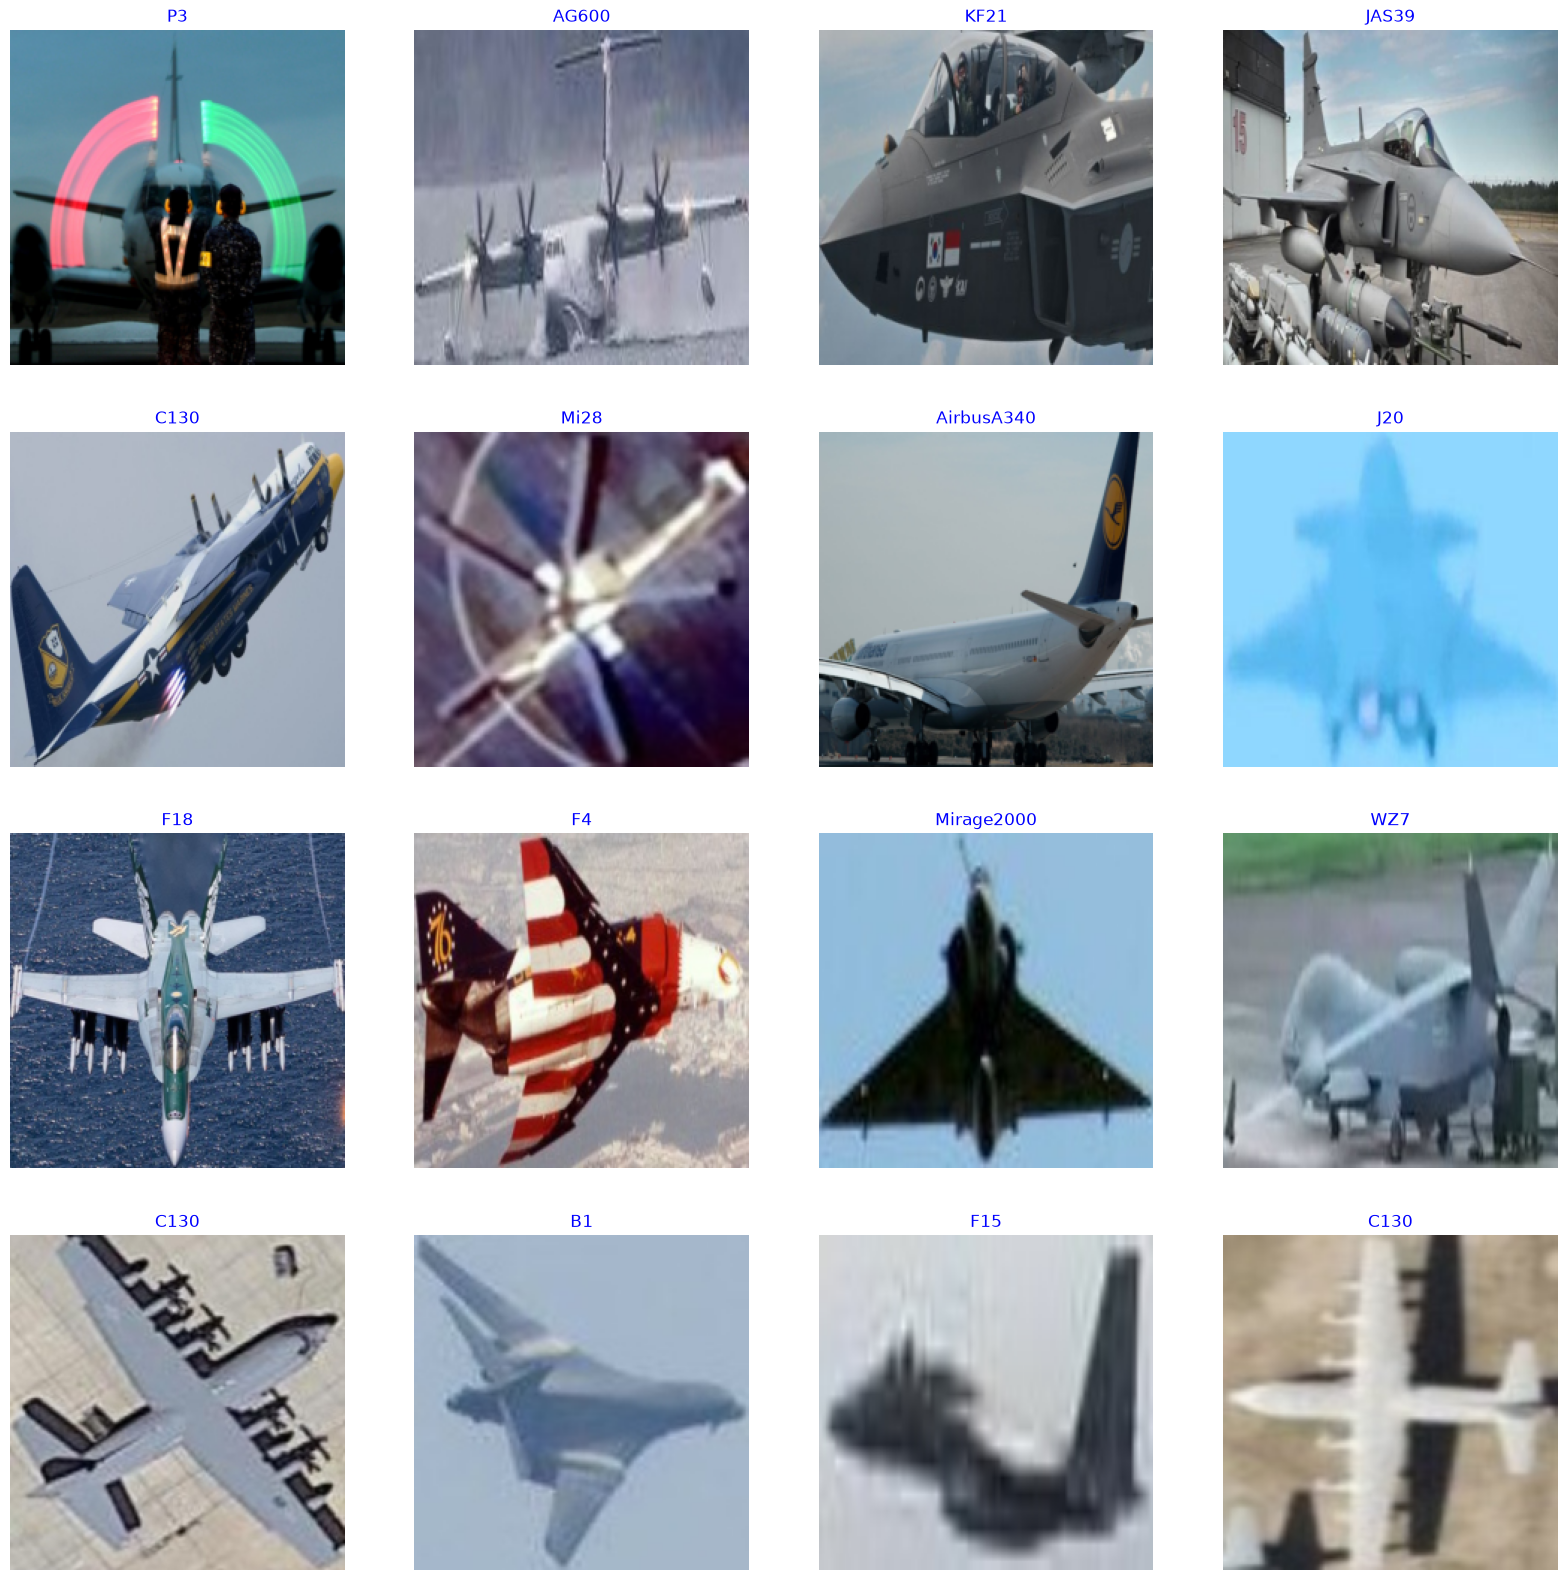

In [9]:
g_dict = class_indices
classes = list(g_dict.keys())

images, labels = next(iter(train_loader))

plt.figure(figsize=(20, 20))

for i in range(min(16, len(images))):
    plt.subplot(4, 4, i + 1)
    image = images[i].permute(1, 2, 0).numpy()
    plt.imshow(image)
    index = labels[i].item()
    class_name = classes[index]
    plt.title(class_name, color='blue', fontsize=12)
    plt.axis('off')
plt.show()

In [10]:
channels = 3
img_shape = (channels, img_size[0], img_size[1])
class_count = len(classes)

class CustomEfficientNetB3(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.base_model = timm.create_model('efficientnet_b3', pretrained=True, num_classes=0, global_pool='max')
        num_features = self.base_model.num_features
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.base_model(x)
        x = self.classifier(x)
        return x

model = CustomEfficientNetB3(num_classes=class_count).to(device)

optimizer = torch.optim.Adamax(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

print(model)

CustomEfficientNetB3(
  (base_model): EfficientNet(
    (conv_stem): Conv2d(3, 40, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(40, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=40, bias=False)
          (bn1): BatchNormAct2d(
            40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(40, 10, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(10, 40, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
         

In [11]:
print("Running Sanity Check on 1 batch...")

sanity_inputs, sanity_labels = next(iter(train_loader))
sanity_inputs, sanity_labels = sanity_inputs.to(device), sanity_labels.to(device)

sanity_model = CustomEfficientNetB3(num_classes=class_count).to(device)
sanity_optimizer = torch.optim.Adamax(sanity_model.parameters(), lr=HP['learning_rate'])
sanity_criterion = nn.CrossEntropyLoss()

sanity_logs = []
sanity_model.train()

for epoch in range(40):
    sanity_optimizer.zero_grad()
    outputs = sanity_model(sanity_inputs)
    loss = sanity_criterion(outputs, sanity_labels)
    loss.backward()
    sanity_optimizer.step()
    
    _, preds = torch.max(outputs, 1)
    acc = (preds == sanity_labels).float().mean().item()
    
    log_line = f"Epoch {epoch+1:02d}/40 - Loss: {loss.item():.4f} - Accuracy: {acc:.4f}"
    sanity_logs.append(log_line)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(log_line)

with open("sanity_check_logs.txt", "w") as f:
    f.write("--- SANITY CHECK LOGS (1 BATCH OVERFITTING TEST) ---\n")
    for line in sanity_logs:
        f.write(line + "\n")

print("Sanity Check completed. Logs saved to 'sanity_check_logs.txt'.")

Running Sanity Check on 1 batch...


Epoch 01/40 - Loss: 6.2477 - Accuracy: 0.0000
Epoch 05/40 - Loss: 0.1533 - Accuracy: 1.0000
Epoch 10/40 - Loss: 0.0066 - Accuracy: 1.0000
Epoch 15/40 - Loss: 0.0038 - Accuracy: 1.0000
Epoch 20/40 - Loss: 0.0104 - Accuracy: 1.0000
Epoch 25/40 - Loss: 0.0007 - Accuracy: 1.0000
Epoch 30/40 - Loss: 0.0119 - Accuracy: 1.0000
Epoch 35/40 - Loss: 0.0088 - Accuracy: 1.0000
Epoch 40/40 - Loss: 0.0003 - Accuracy: 1.0000
Sanity Check completed. Logs saved to 'sanity_check_logs.txt'.


In [12]:
from tqdm import tqdm
from torch.utils.tensorboard import SummaryWriter

writer = SummaryWriter(log_dir='./runs/aircraft_experiment')

writer.add_hparams(
    hparam_dict={
        'lr': HP['learning_rate'],
        'batch_size': HP['batch_size'],
        'optimizer': HP['optimizer'],
        'dropout': HP['dropout_rate'],
        'dense_units': HP['dense_units']
    },
    metric_dict={'hparam/val_loss': 0.0, 'hparam/val_accuracy': 0.0}
)

class EarlyStoppingPyTorch:
    def __init__(self, patience=3, restore_best_weights=True, save_path='best_model.pth'):
        self.patience = patience
        self.restore_best_weights = restore_best_weights
        self.save_path = save_path
        self.best_loss = float('inf')
        self.counter = 0
        self.best_state = None
        self.early_stop = False

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            self.counter = 0
            if self.restore_best_weights:
                self.best_state = model.state_dict()

            torch.save(model.state_dict(), self.save_path)
            print(f" -> Validation loss improved. Checkpoint saved to {self.save_path}")
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
                if self.restore_best_weights and self.best_state is not None:
                    model.load_state_dict(self.best_state)

early_stopping = EarlyStoppingPyTorch(patience=2, restore_best_weights=True)

epochs = HP['epochs']
history = {'accuracy': [], 'loss': [], 'val_accuracy': [], 'val_loss': []}

for epoch in range(epochs):
    model.train()
    running_loss, running_corrects, total_samples = 0.0, 0, 0
    
    train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", leave=False)
    for inputs, labels in train_loop:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        _, preds = torch.max(outputs, 1)
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data).item()
        total_samples += inputs.size(0)
        
        train_loop.set_postfix(loss=loss.item())
        
    epoch_loss = running_loss / total_samples
    epoch_acc = running_corrects / total_samples
    
    model.eval()
    val_running_loss, val_running_corrects, val_total_samples = 0.0, 0, 0
    
    valid_loop = tqdm(valid_loader, desc=f"Epoch {epoch+1}/{epochs} [Valid]", leave=False)
    with torch.no_grad():
        for inputs, labels in valid_loop:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            _, preds = torch.max(outputs, 1)
            val_running_loss += loss.item() * inputs.size(0)
            val_running_corrects += torch.sum(preds == labels.data).item()
            val_total_samples += inputs.size(0)
            
            valid_loop.set_postfix(val_loss=loss.item())
            
    val_loss = val_running_loss / val_total_samples
    val_acc = val_running_corrects / val_total_samples
    
    history['accuracy'].append(epoch_acc)
    history['loss'].append(epoch_loss)
    history['val_accuracy'].append(val_acc)
    history['val_loss'].append(val_loss)
    
    writer.add_scalar('Loss/Train', epoch_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('Accuracy/Train', epoch_acc, epoch)
    writer.add_scalar('Accuracy/Validation', val_acc, epoch)
    
    print(f'Epoch {epoch+1}/{epochs} - loss: {epoch_loss:.4f} - accuracy: {epoch_acc:.4f} - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}')
    
    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print(f"Early stopping triggered at epoch {epoch+1}")
        break

writer.close()

Epoch 1/20 - loss: 3.1651 - accuracy: 0.2812 - val_loss: 1.6294 - val_accuracy: 0.5910
 -> Validation loss improved. Checkpoint saved to best_model.pth


Epoch 2/20 - loss: 1.4728 - accuracy: 0.6229 - val_loss: 1.0699 - val_accuracy: 0.7270
 -> Validation loss improved. Checkpoint saved to best_model.pth


Epoch 3/20 - loss: 0.8449 - accuracy: 0.7687 - val_loss: 0.8601 - val_accuracy: 0.7848
 -> Validation loss improved. Checkpoint saved to best_model.pth


Epoch 4/20 - loss: 0.5413 - accuracy: 0.8460 - val_loss: 0.8076 - val_accuracy: 0.7994
 -> Validation loss improved. Checkpoint saved to best_model.pth


Epoch 5/20 - loss: 0.3792 - accuracy: 0.8887 - val_loss: 0.8435 - val_accuracy: 0.8065


Epoch 6/20 - loss: 0.2714 - accuracy: 0.9178 - val_loss: 0.8501 - val_accuracy: 0.8121
Early stopping triggered at epoch 6


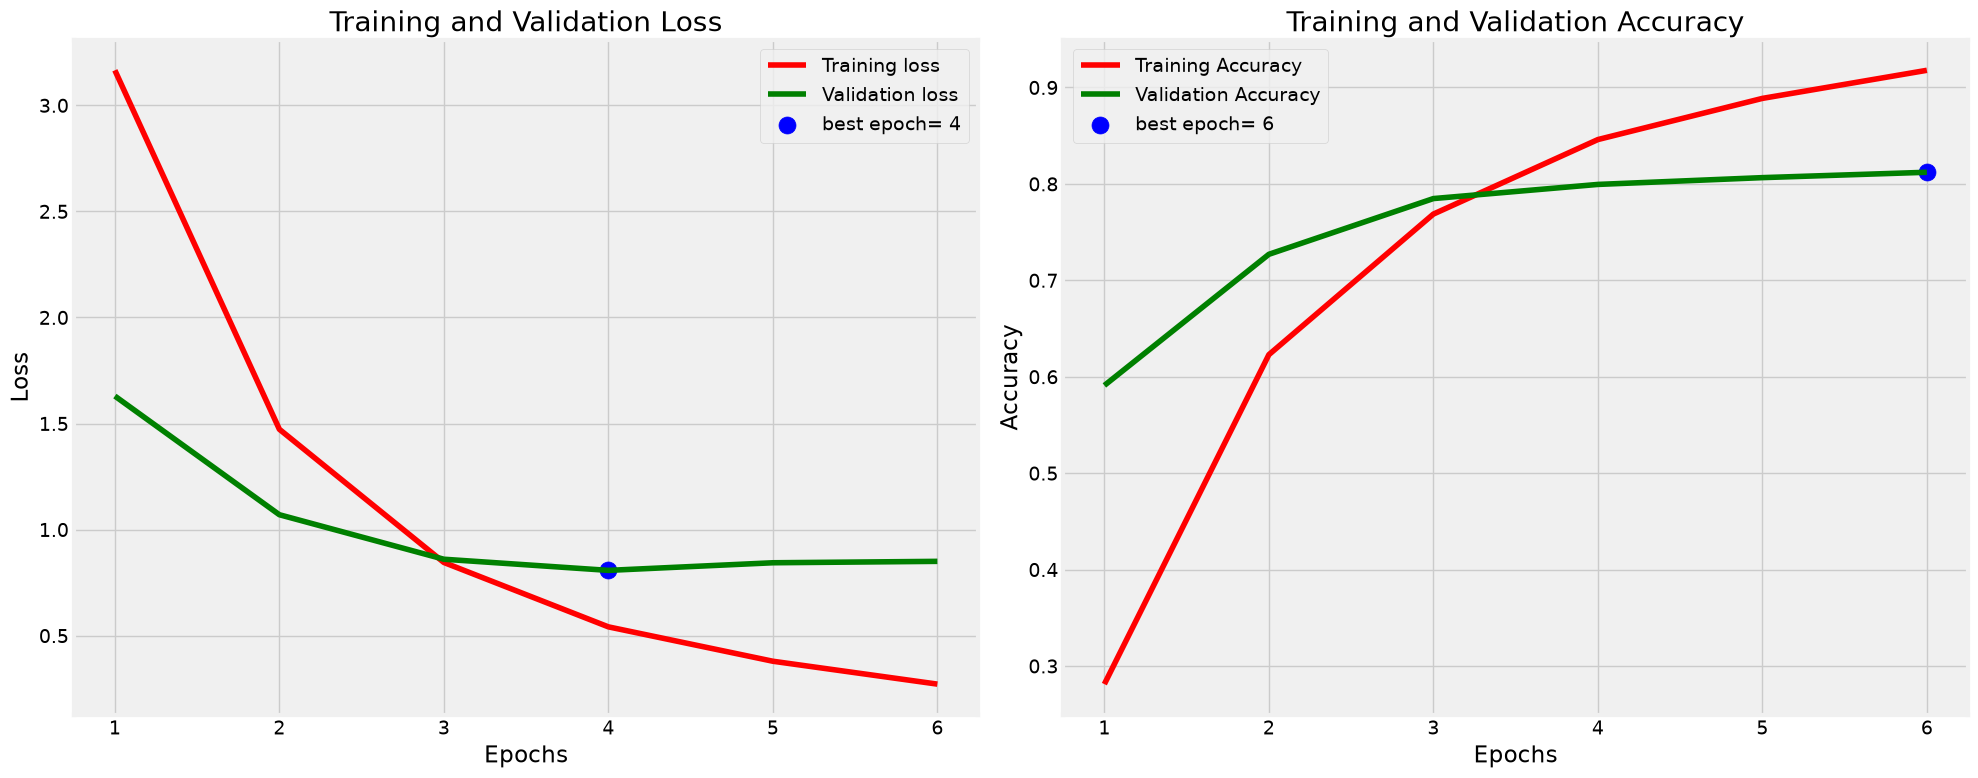

In [13]:
# Plot Accuracy and Loss
tr_acc = history['accuracy']
tr_loss = history['loss']
val_acc = history['val_accuracy']
val_loss = history['val_loss']
index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]

Epochs = [i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(index_loss + 1)}'
acc_label = f'best epoch= {str(index_acc + 1)}'

# Plot training history
plt.figure(figsize=(20, 8))
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label='Training loss')
plt.plot(Epochs, val_loss, 'g', label='Validation loss')
plt.scatter(index_loss + 1, val_lowest, s=150, c='blue', label=loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label='Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label='Validation Accuracy')
plt.scatter(index_acc + 1, acc_highest, s=150, c='blue', label=acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
def evaluate_loader(loader):
    model.eval()
    running_loss, running_corrects, total_samples = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data).item()
            total_samples += inputs.size(0)
            
    return running_loss / total_samples, running_corrects / total_samples

train_score = evaluate_loader(train_loader)
valid_score = evaluate_loader(valid_loader)
test_score = evaluate_loader(test_loader)

print("Train Loss: ", train_score[0])
print("Train Accuracy: ", train_score[1])
print('-' * 20)
print("Validation Loss: ", valid_score[0])
print("Validation Accuracy: ", valid_score[1])
print('-' * 20)
print("Test Loss: ", test_score[0])
print("Test Accuracy: ", test_score[1])

Train Loss:  0.08476756072390286
Train Accuracy:  0.9771412400955855
--------------------
Validation Loss:  0.8501344757081346
Validation Accuracy:  0.8120598591549296
--------------------
Test Loss:  0.8481764155597872
Test Accuracy:  0.8114453411592076


In [15]:
# Get Predictions
model.eval()
all_preds = []
with torch.no_grad():
    for inputs, _ in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = torch.softmax(outputs, dim=1)
        all_preds.append(preds.cpu().numpy())

preds = np.concatenate(all_preds, axis=0)
y_pred = np.argmax(preds, axis=1)
classes = list(class_indices.keys())

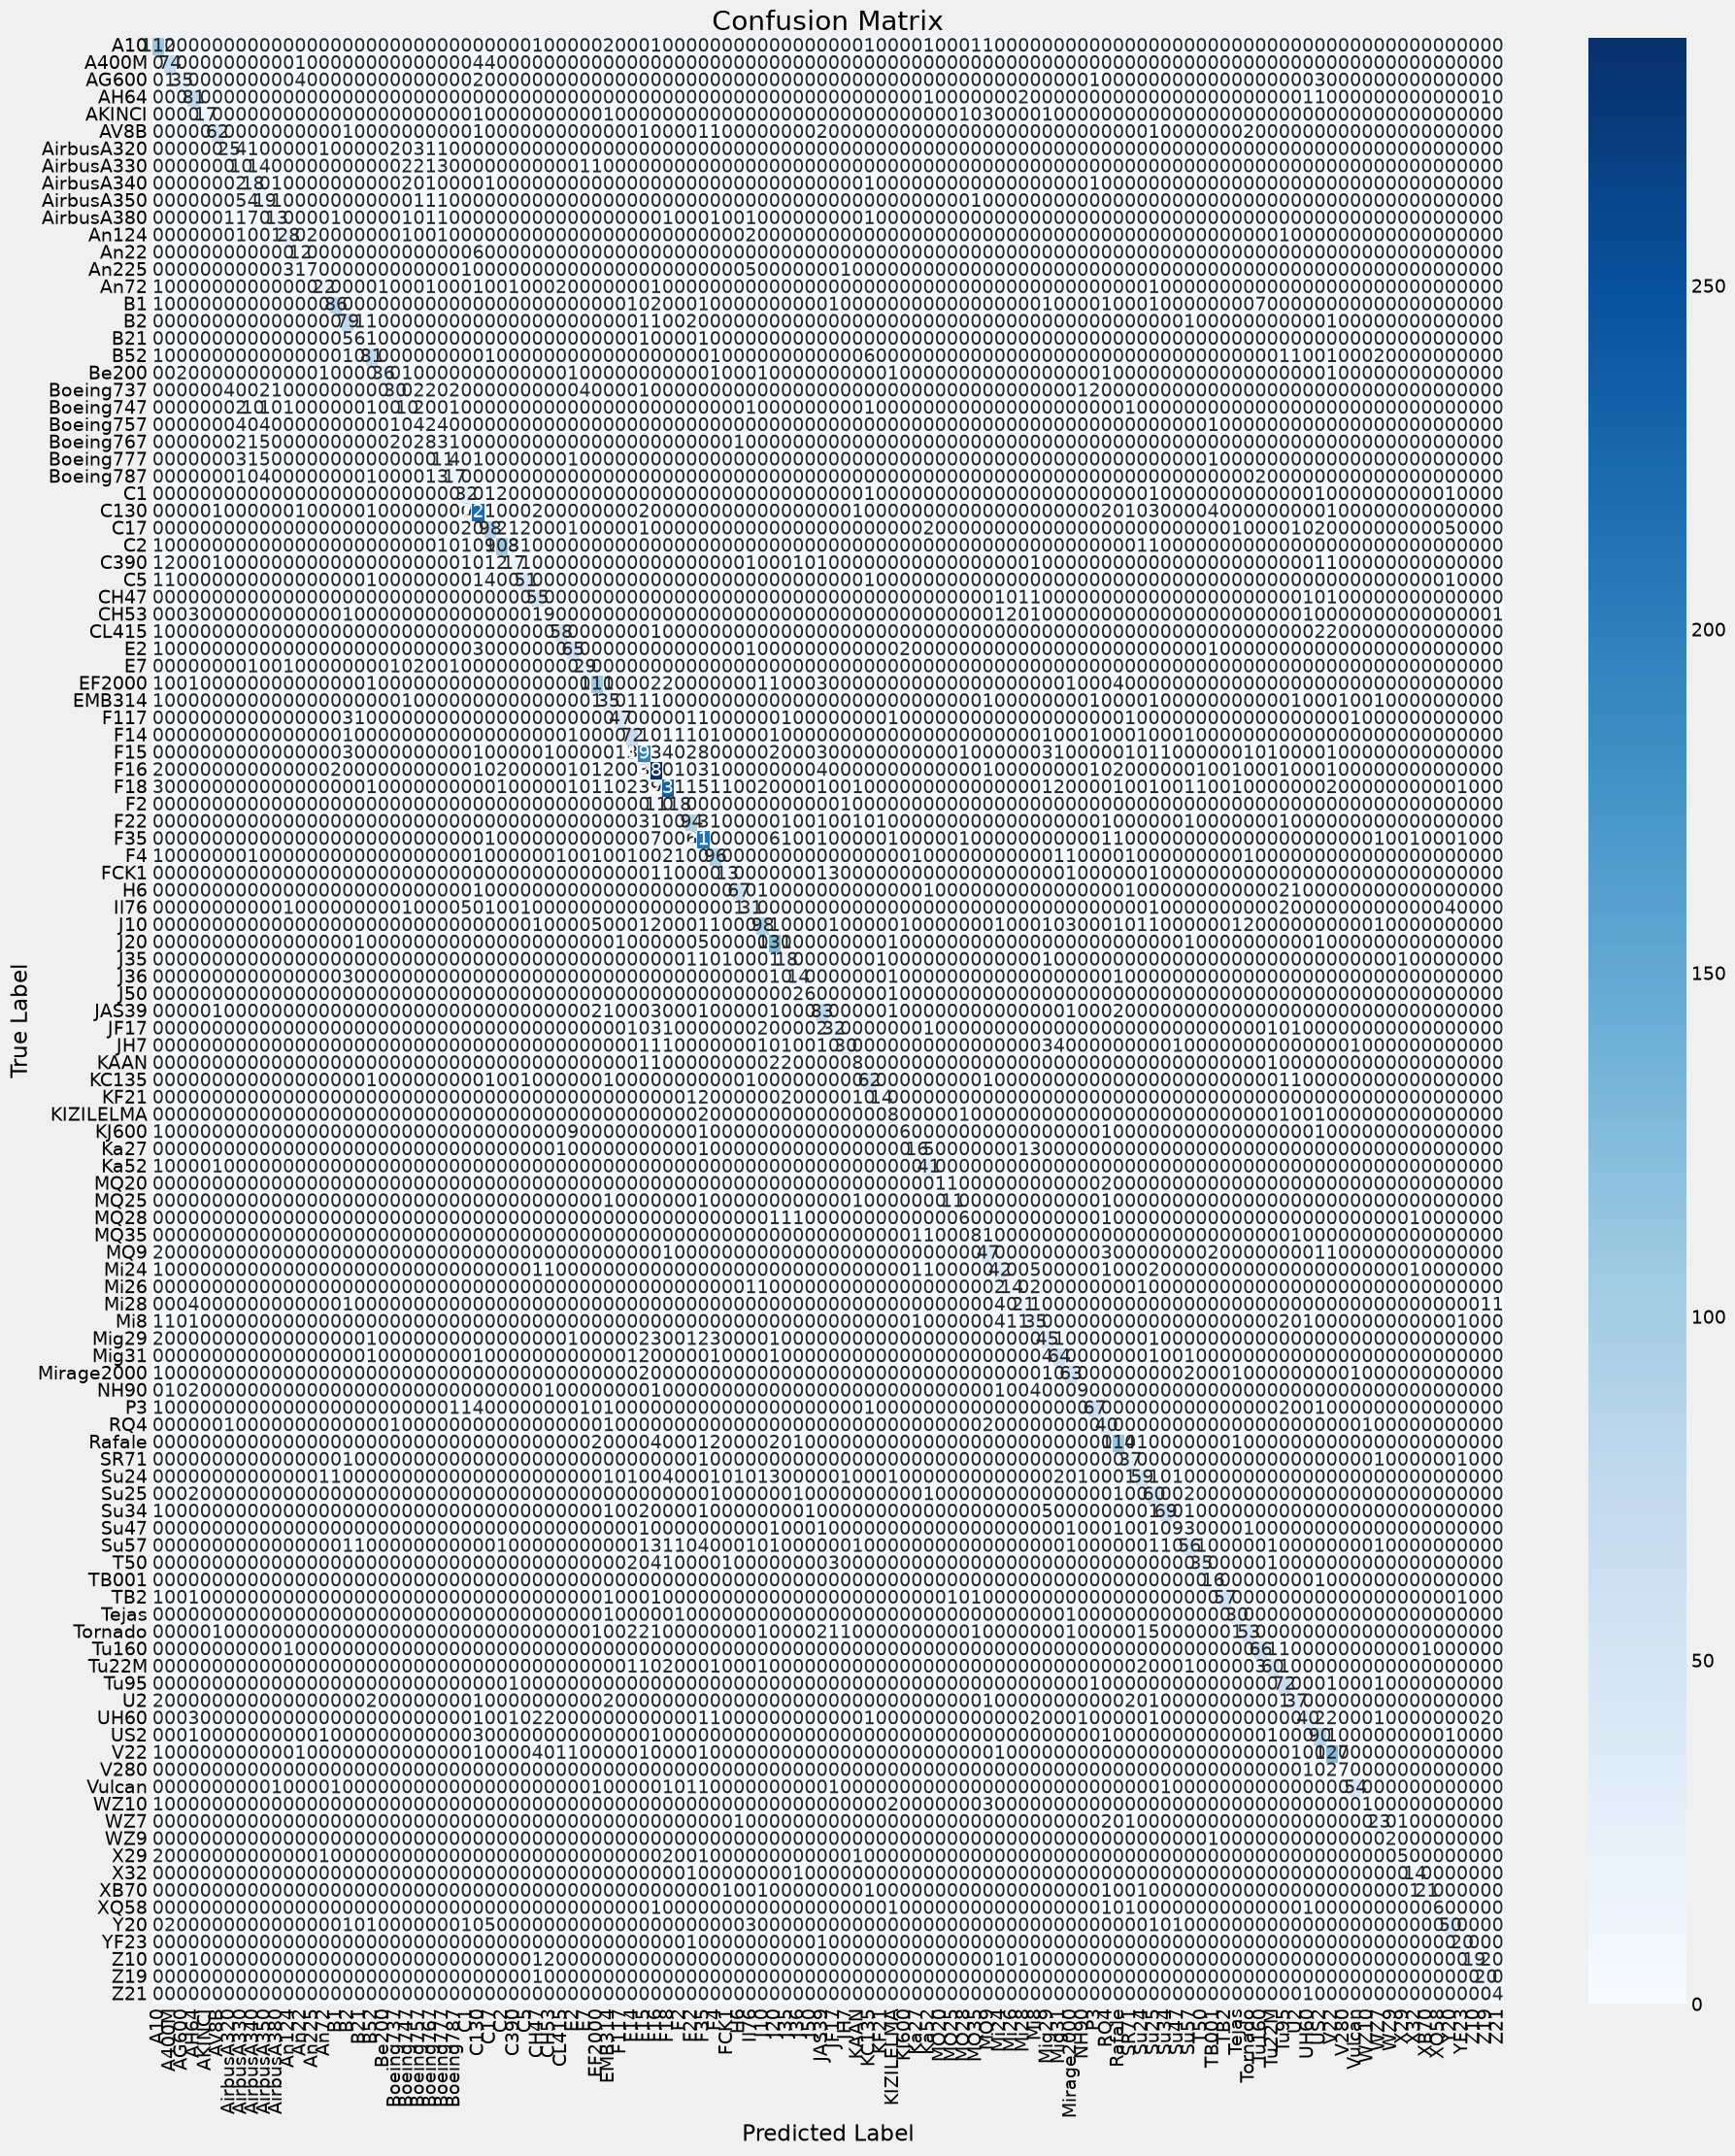

              precision    recall  f1-score   support

         A10       0.77      0.93      0.84       120
       A400M       0.90      0.89      0.90        83
       AG600       0.95      0.76      0.84        46
        AH64       0.81      0.93      0.87        87
      AKINCI       1.00      0.71      0.83        24
        AV8B       0.93      0.86      0.89        72
  AirbusA320       0.81      0.66      0.72        38
  AirbusA330       0.29      0.40      0.33        25
  AirbusA340       0.40      0.67      0.50        27
  AirbusA350       0.43      0.58      0.49        33
  AirbusA380       0.72      0.43      0.54        30
       An124       0.80      0.76      0.78        37
        An22       0.60      0.67      0.63        18
       An225       0.78      0.39      0.52        18
        An72       0.81      0.71      0.76        31
          B1       0.95      0.84      0.89       102
          B2       0.78      0.91      0.84        87
         B21       0.60    

In [16]:
plt.figure(figsize=(20, 25))
test_targets = test_dataset.df['labels'].map(class_indices).values
cm = confusion_matrix(test_targets, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print(classification_report(test_targets, y_pred, target_names=classes))

In [17]:
torch.save(model.state_dict(), 'military_aircraft_classification.pth')